Importing Python Libraries

In this step, we import the Python libraries needed for data analysis, video processing and heart rate estimation.

We use OpenCV (`cv2`) to read and process video files. NumPy is used for numerical calculations, and pandas is used to read CSV data. Matplotlib is used to plot graphs and show the results.

We also import `butter` and `sosfiltfilt` from SciPy to filter the signals and reduce unwanted noise. The `find_peaks` function is used to detect peaks in the signal and help estimate heart rate.

In [19]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt, find_peaks


In [20]:
import os
def save_fig(filename):
    os.makedirs("figures", exist_ok=True)
    plt.tight_layout()
    plt.savefig("figures/" + filename + ".png", dpi=300 )

Heart Rate Estimation Using Filtering and FFT

In this step, we use a band-pass filter and Fast Fourier Transform (FFT) to estimate heart rate.

First, we check the signal and sampling frequency to make sure they are valid. Then, we use a band-pass filter to keep frequencies between 40 and 200 BPM. This helps reduce unwanted noise and slow changes in the signal.

Next, we use FFT to change the signal from the time domain to the frequency domain. We find the frequency with the highest amplitude within the selected range.

Finally, we multiply this frequency by 60 to estimate heart rate in beats per minute (BPM). The function also returns the filtered signal and FFT data for further analysis.

In [21]:
def estimate_hr(signal, fs, bpm_range=(40, 200), filter_order=3):
    """
    Estimate heart rate using a band-pass filter and FFT.

    Parameters
    ----------
    signal : array-like
        The input optical or video signal.
    fs : float
        The sampling frequency in Hz.
    bpm_range : tuple
        The heart rate range in BPM. Default is (40, 200).
    filter_order : int
        The order of the band-pass filter. Default is 3.

    Returns
    -------
    dict
        A dictionary containing:
        bpm_fft : estimated heart rate in BPM.
        dominant_hz : dominant frequency in Hz.
        filtered : filtered signal.
        freqs_hz : FFT frequency values in Hz.
        spectrum : FFT magnitude values.
    """
    x = np.asarray(signal, dtype=float)

    if not np.all(np.isfinite(x)):
        raise ValueError("Signal contains invalid values.")

    if not np.isfinite(fs) or fs <= 0:
        raise ValueError("Invalid sampling frequency.")

    low_bpm, high_bpm = bpm_range
    low_hz, high_hz = low_bpm / 60, high_bpm / 60

    if not (0 < low_hz < high_hz < fs / 2):
        raise ValueError("Invalid frequency range.")
    
    sos = butter(filter_order, [low_hz, high_hz], btype="bandpass", fs=fs, output="sos")
    filtered = sosfiltfilt(sos, x)

    freqs = np.fft.rfftfreq(len(filtered), d=1 / fs)
    spectrum = np.abs(np.fft.rfft(filtered - np.mean(filtered)))
   
    within_range = (freqs >= low_hz) & (freqs <= high_hz)
    dominant_hz = freqs[within_range][np.argmax(spectrum[within_range])]
    
    return {"bpm_fft": float(dominant_hz * 60),
            "dominant_hz": float(dominant_hz),
            "filtered": filtered, "freqs_hz": freqs, "spectrum": spectrum}

Loading and Plotting the Optical Sensor Data

In this step, we use Python to read the CSV file. The file contains two columns: time in seconds and optical signal intensity.

First, we check if there are any missing values or problems with the time data. Then, we calculate the sampling frequency using the time difference between samples.

Finally, we plot the optical signal against time. This helps us see how the signal changes and check the original data before further analysis.

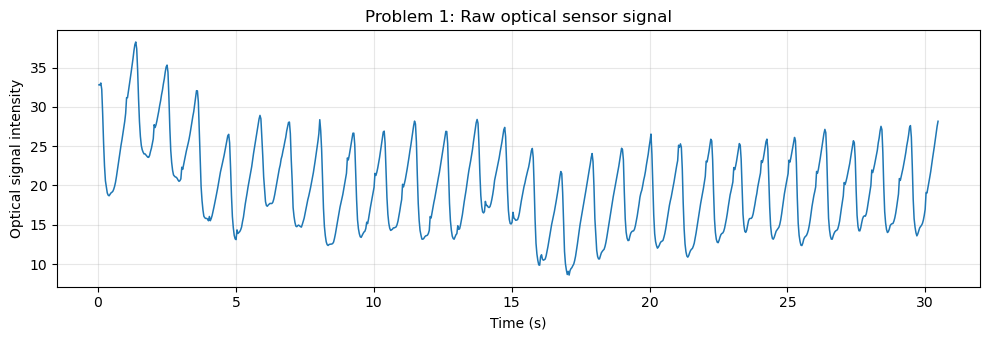

In [22]:
df = pd.read_csv("data/heart_beat_signal.csv", header=None, names=["time_s", "intensity"])

if df.isna().any().any():
    raise ValueError("Missing values found in CSV data.")

t = df["time_s"].to_numpy(dtype=float)
signal = df["intensity"].to_numpy(dtype=float)

dt = np.diff(t)
if np.any(dt <= 0):
    raise ValueError("Time values must be strictly increasing.")
fs = 1 / np.median(dt)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, signal, linewidth=1.1)
ax.set(xlabel="Time (s)", ylabel="Optical signal intensity", title="Problem 1: Raw optical sensor signal")
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig("problem1_raw_signal")
plt.show()

Calculating the Estimated Heart Rate

In this step, we use the `estimate_hr` function to calculate heart rate from the optical sensor data.

The function uses the signal and sampling frequency as inputs. It applies a band-pass filter and FFT to find the main frequency of the signal.

Finally, we print the estimated heart rate in beats per minute (BPM), showing the result to two decimal places.

In [23]:
result = estimate_hr(signal, fs)
print(f"FFT estimated heart rate: {result['bpm_fft']:.2f} BPM")

FFT estimated heart rate: 55.26 BPM


Comparing Raw and Filtered Signals

In this step, we plot the raw signal and the filtered signal on the same graph.

The raw signal shows the original data from the optical sensor. The filtered signal shows the data after using the band-pass filter.

By comparing these two signals, we can see how filtering changes the signal. The filter helps reduce unwanted noise and slow changes, making the heart rate signal easier to study.

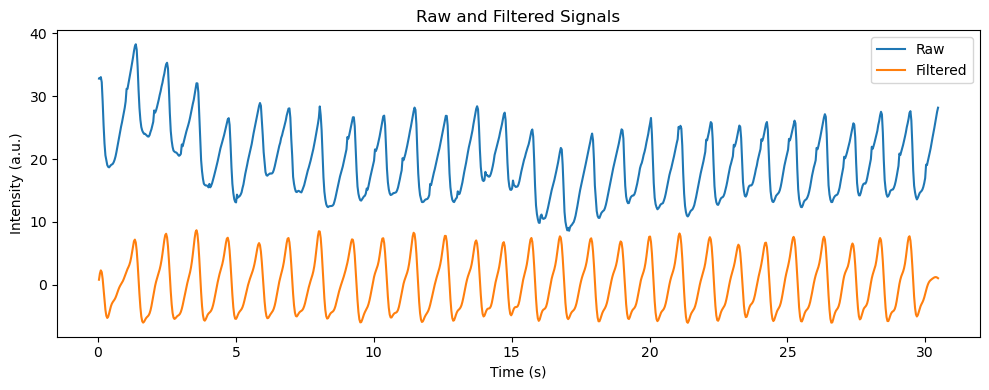

In [24]:
plt.figure(figsize=(10, 4))
plt.plot(t, signal, label="Raw")
plt.plot(t, result["filtered"], label="Filtered")
plt.xlabel("Time (s)")
plt.ylabel("Intensity (a.u.)")
plt.title("Raw and Filtered Signals")
plt.legend()
save_fig("problem1_raw_vs_filtered")
plt.show()

Plotting the FFT Frequency Spectrum

In this step, we plot the FFT frequency spectrum to show the different frequencies in the filtered signal.

The x-axis shows the frequency in BPM, and the y-axis shows the FFT magnitude. The red dashed line shows the estimated heart rate from the FFT method.

This graph helps us see the main frequency of the signal and understand how the heart rate is estimated.

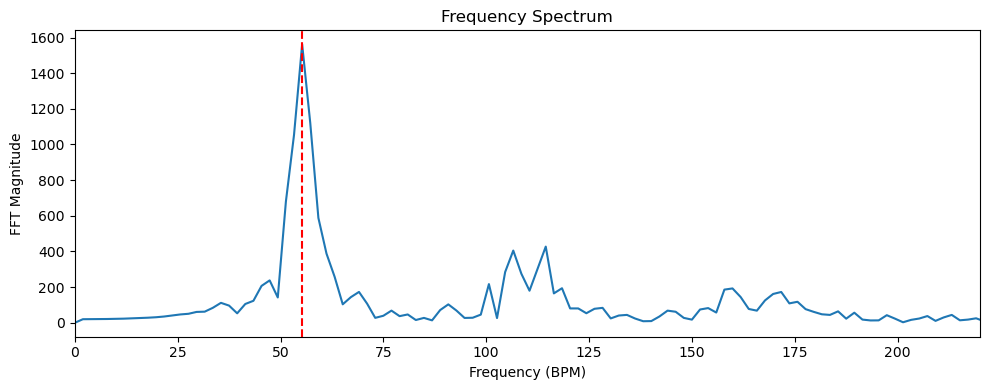

In [25]:
plt.figure(figsize=(10, 4))
plt.plot(result["freqs_hz"] * 60, result["spectrum"])
plt.axvline(result["bpm_fft"], linestyle="--", color="red")
plt.xlim(0, 220)
plt.xlabel("Frequency (BPM)")
plt.ylabel("FFT Magnitude")
plt.title("Frequency Spectrum")
save_fig("problem1_frequency_spectrum")
plt.show()

Heart Rate Estimation Using Peak Detection

In this step, we use peak detection to estimate heart rate from the filtered signal.

First, we use the `find_peaks` function to find peaks in the signal. We set a minimum distance and prominence to reduce noise and avoid detecting too many small peaks.

If at least two peaks are found, we calculate the average time between the peaks. We then use this value to estimate heart rate in BPM.

Finally, we compare the result with the FFT heart rate and calculate the difference between the two methods. This helps us check if the results are similar.

In [26]:
filtered = result["filtered"]

peaks, _ = find_peaks(
    filtered,
    distance=max(1, int(fs * 60 / 200)),
    prominence=0.35 * np.std(filtered)
)

if len(peaks) >= 2:
    bpm_peaks = 60 / np.mean(np.diff(t[peaks]))
    print(f"Peak detection HR: {bpm_peaks:.2f} BPM")
    print(f"FFT HR: {result['bpm_fft']:.2f} BPM")
    print(f"Difference: {abs(result['bpm_fft'] - bpm_peaks):.2f} BPM")
else:
    print("Too few peaks detected.")

Peak detection HR: 55.24 BPM
FFT HR: 55.26 BPM
Difference: 0.02 BPM


Plotting the Peak Detection Results

In this step, we plot the filtered signal and the detected peaks on the same graph.

The line shows how the filtered signal changes over time. The points show the peaks found by the `find_peaks` function.

The x-axis shows time in seconds, and the y-axis shows the filtered signal intensity.

This graph helps us see where the peaks are detected and check if the peak detection method works well.

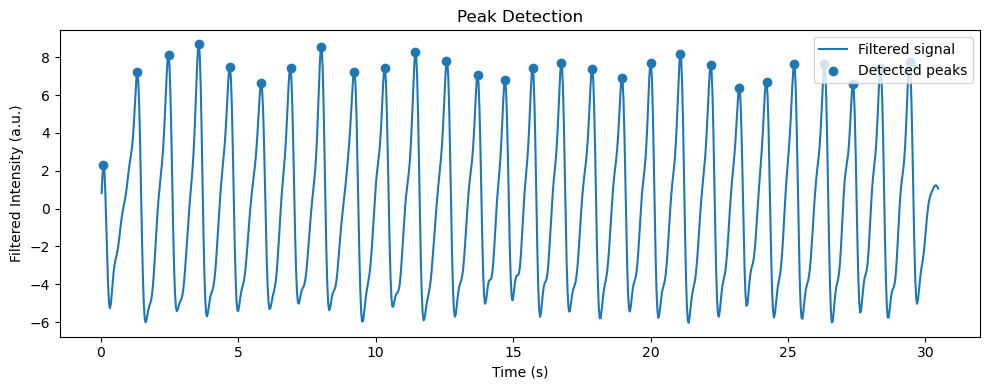

In [27]:
plt.figure(figsize=(10, 4))
plt.plot(t, filtered, label="Filtered signal")
plt.scatter(t[peaks], filtered[peaks], label="Detected peaks")
plt.xlabel("Time (s)")
plt.ylabel("Filtered Intensity (a.u.)")
plt.title("Peak Detection")
plt.legend()
save_fig("problem1_peak_detection")
plt.show()

Sensitivity Analysis of Filter Order

In this step, we test how different filter orders affect the heart rate estimation.

We use four different filter orders: 2, 3, 4 and 5. For each order, we use the same function to calculate the heart rate using FFT.

We also calculate the standard deviation (SD) of the filtered signal to see how much the signal values change.

Finally, we compare the results to check if changing the filter order has a large effect on the estimated heart rate. This helps us understand how stable our method is.

In [28]:
for order in [2, 3, 4, 5]:
    trial = estimate_hr(signal, fs, filter_order=order)
    print(f"Filter order: {order} | FFT HR: {trial['bpm_fft']:.2f} BPM | Filtered SD: {np.std(trial['filtered']):.3f}")

Filter order: 2 | FFT HR: 55.26 BPM | Filtered SD: 3.923
Filter order: 3 | FFT HR: 55.26 BPM | Filtered SD: 4.149
Filter order: 4 | FFT HR: 55.26 BPM | Filtered SD: 4.240
Filter order: 5 | FFT HR: 55.26 BPM | Filtered SD: 4.279


Sensitivity Analysis of Signal Duration

In this step, we test how the length of the signal affects the estimated heart rate.

We use four different durations: 10, 15, 20 and 30 seconds. For each duration, we select the data from the beginning of the signal and use FFT to estimate heart rate.

We then compare the results to see if the heart rate changes when different amounts of data are used.

This helps us understand how the signal length affects the results and how stable our method is.

In [29]:
for duration in [10, 15, 20, 30]:
    subset = t < t[0] + duration
    trial = estimate_hr(signal[subset], fs)
    print(f"Duration: {duration}s | FFT HR: {trial['bpm_fft']:.2f} BPM")


Duration: 10s | FFT HR: 54.05 BPM
Duration: 15s | FFT HR: 52.05 BPM
Duration: 20s | FFT HR: 54.05 BPM
Duration: 30s | FFT HR: 56.06 BPM


Sensitivity Analysis of Peak Prominence

In this step, we test how different prominence values affect peak detection and heart rate estimation.

We use three different factors: 0.1, 0.35 and 0.7. These values are multiplied by the standard deviation of the filtered signal to set the minimum peak prominence.

For each factor, we count the detected peaks and calculate heart rate using the average time between peaks.

Finally, we compare the results to see how changing the prominence affects the number of peaks and the estimated heart rate. This helps us understand how sensitive the peak detection method is to this parameter.

In [30]:
for factor in [0.1, 0.35, 0.7]:
    test_peaks, _ = find_peaks(
        filtered,
        distance=max(1, int(fs * 60 / 200)),
        prominence=factor * np.std(filtered)
    )

    if len(test_peaks) >= 2:
        test_hr = 60 / np.mean(np.diff(t[test_peaks]))
        print(f"Prominence: {factor} | Peaks: {len(test_peaks)} | HR: {test_hr:.2f} BPM")
    else:
        print(f"Prominence: {factor} | Too few peaks")

Prominence: 0.1 | Peaks: 28 | HR: 55.24 BPM
Prominence: 0.35 | Peaks: 28 | HR: 55.24 BPM
Prominence: 0.7 | Peaks: 27 | HR: 55.53 BPM


Reading the Video and Calculating Mean Grayscale Values

In this step, we use OpenCV to read the video of a finger placed over the camera lens.

First, we get the frame rate and the total number of frames. We use these values to calculate the video duration.

Next, we read the video frame by frame and change each frame into a grayscale image. We then calculate the average grayscale value of each frame and save it in a list called `mean_gray`.

Finally, we close the video file and print the number of frames processed. These grayscale values will be used to study changes in light intensity and estimate heart rate.

In [31]:
video = cv2.VideoCapture('data/video_of_finger.MOV')

fps = video.get(cv2.CAP_PROP_FPS)
frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

print(f"Frames per second: {fps:.2f}")
print(f"Total number of frames: {frames:.0f}")
print(f"Duration of video (seconds): {frames / fps:.2f}")

mean_gray = []

while True:
    ret, frame = video.read()
    if not ret:
        break

    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    mean_gray.append(np.mean(gray_frame))

video.release()

print(f"Frames processed: {len(mean_gray)}")

Frames per second: 29.98
Total number of frames: 1852
Duration of video (seconds): 61.78
Frames processed: 1852


Plotting the Mean Grayscale Value Over Time

In this step, we plot the average grayscale value of each video frame against time.

First, we use the frame rate to calculate the time for each frame. Then, we plot the mean grayscale values to show how the brightness changes during the video.

The x-axis shows time in seconds, and the y-axis shows the mean grayscale value.

This graph helps us observe changes in light intensity over time and check for possible patterns related to the heartbeat.

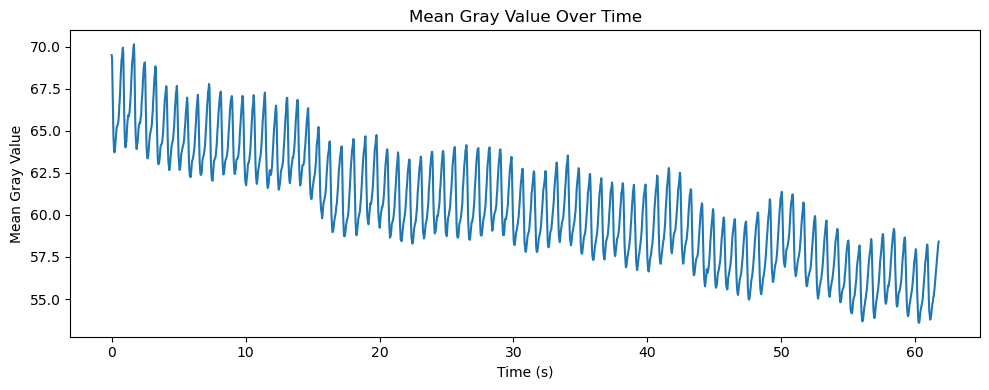

In [32]:
time = np.arange(len(mean_gray)) / fps

plt.figure(figsize=(10, 4))
plt.plot(time, mean_gray)
plt.xlabel("Time (s)")
plt.ylabel("Mean Gray Value")
plt.title("Mean Gray Value Over Time")
plt.tight_layout()
save_fig("problem2_mean_gray_value")
plt.show()

Calculating and Displaying the Estimated Heart Rate

In this step, we use the `estimate_hr` function to calculate heart rate from the video signal.

We use the mean grayscale values as the input signal and the video frame rate as the sampling frequency.

The function uses a band-pass filter and FFT to estimate the heart rate. Finally, we print the result in beats per minute (BPM).

In [33]:
video_results = estimate_hr(mean_gray, fs=fps)
print(f"Estimated Heart Rate (BPM): {video_results['bpm_fft']:.2f}")

Estimated Heart Rate (BPM): 71.87


Plotting the Filtered Video Signal

In this step, we plot the filtered grayscale signal over time.

The signal has been processed using a band-pass filter to reduce unwanted noise and slow changes in brightness.

The x-axis shows time in seconds, and the y-axis shows the filtered grayscale value.

This graph helps us observe changes in the filtered signal and see possible patterns related to the heartbeat.

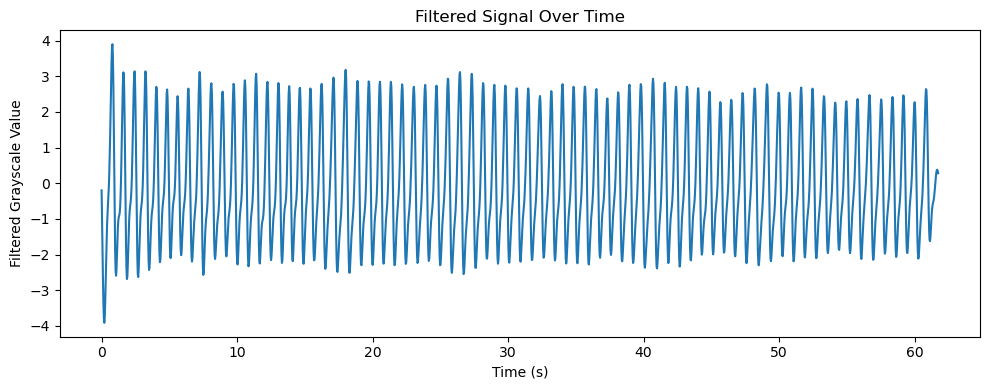

In [34]:
plt.figure(figsize=(10, 4))
plt.plot(time, video_results["filtered"])
plt.xlabel("Time (s)")
plt.ylabel("Filtered Grayscale Value")
plt.title("Filtered Signal Over Time")
plt.tight_layout()
save_fig("problem2_filtered_signal")
plt.show()

Plotting the FFT Frequency Spectrum

In this step, we plot the FFT frequency spectrum of the filtered video signal.

The x-axis shows the frequency in BPM, and the y-axis shows the FFT magnitude.

The red dashed line shows the estimated heart rate. We focus on the frequency range from 40 to 200 BPM.

This graph helps us find the main frequency of the signal and understand how the heart rate is estimated from the video.

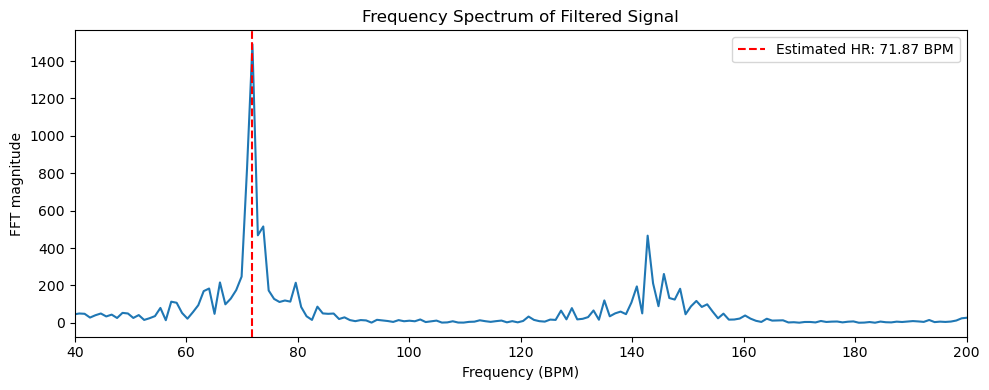

In [35]:
plt.figure(figsize=(10, 4))
plt.plot(video_results["freqs_hz"]*60, video_results["spectrum"])
plt.axvline(video_results["bpm_fft"], color='r', linestyle='--', label=f"Estimated HR: {video_results['bpm_fft']:.2f} BPM")
plt.xlim(40, 200)
plt.xlabel("Frequency (BPM)")
plt.ylabel("FFT magnitude")
plt.title("Frequency Spectrum of Filtered Signal")
plt.legend()
plt.tight_layout()
save_fig("problem2_frequency_spectrum")
plt.show()